# SiN Grating Coupler -- Conventional Grating, Adam-Optimized (Step 2)

The **conventional** grating has one meta-atom per period: an unetched SiN tooth of
width w and an etched groove filling the rest of the period, with etch depth e. The
period P is fixed by first-order phase matching (Step 1), so the free parameters are
**w and e**. They are optimized for the SMF-28 coupling efficiency η at 1.35 µm with the
same method that Step 3 applies to the meta grating: Meep adjoint gradients and Adam with
a projection onto the constraints (every width ≥ 100 nm, widths summing to at most P,
etch between 20 nm and the full 400 nm).

The platform, resolution, period and BOX thickness all come from Step 1
(`meta/data/step1/summary.json`). η and its gradient are computed on the differentiable
`MaterialGrid` at the optimization resolution; the final design is re-evaluated at
res 160.

Because there are only two free parameters, the whole (w, e) landscape is also mapped
directly. That shows whether Adam finds the global optimum and gives Step 3 an honest
baseline: the best a conventional grating can do on this platform.

**Do not use "Run All."** Each optimization runs for hours; every section caches or
checkpoints its results in `meta/data/step2/` and resumes after an interruption.

## 0. Setup

In [1]:
# Imports, style, the Step 1 settings, and the common parameters of every run here.
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pic_toolkit.meep_sim import sin_grating as sg
from pic_toolkit import style

style.apply_style()
CACHE = Path.cwd().parent / "data" / "step2"
S1 = json.loads((Path.cwd().parent / "data" / "step1" / "summary.json").read_text())
RES, P, BOX = S1["res_opt"], S1["period_design_um"], S1["box_um"]
COMMON = {"resolution": RES, "period_um": P, "box_um": BOX, "n_atoms": 1}
ADAM = {"n_iter": 30, "lr0": 0.02, "lr1": 0.002}       # shared with Step 3
print(f"optimization resolution {RES} px/um, period {P} um, BOX {BOX} um, {sg.DEFAULT_PARAMS['n_periods']} periods; "
      f"Adam: {ADAM}")


def design(w, etch, n_atoms=1, **kw):
    # Parameter dict for a design; for one atom the groove is P - w.
    widths = [w, P - w] if n_atoms == 1 else list(w)
    return {**COMMON, "n_atoms": n_atoms, "widths_um": widths, "etch_um": etch, **kw}

optimization resolution 60 px/um, period 0.926 um, BOX 4.58 um, 22 periods; Adam: {'n_iter': 30, 'lr0': 0.02, 'lr1': 0.002}


## 1. The (w, e) landscape

η at 1.35 µm (fiber at its best position) on a 7 × 7 grid of tooth widths and etch
depths, at the optimization resolution. The extremes are a nearly unetched slab
(no scattering) and a deep, full-period trench (very strong scattering, so the light
leaves within a few periods and the beam is far narrower than the fiber mode). The
optimum sits between, where the grating strength matches the 9.2 µm fiber mode.

In [2]:
W_GRID = np.round(np.linspace(0.15, P - 0.15, 7), 3)
E_GRID = np.round(np.linspace(0.05, 0.40, 7), 3)


def landscape():
    out = np.zeros((len(E_GRID), len(W_GRID)))
    for i, e in enumerate(E_GRID):
        for j, w in enumerate(W_GRID):
            out[i, j] = sg.best_x0(sg.run_forward(design(w, e), "grid"))[1]
            print(f"  etch {e:.3f}, tooth {w:.3f}: eta {out[i, j]:.4f}", flush=True)
    return out


LAND = sg.cached(CACHE / "landscape.pkl", landscape)
i, j = np.unravel_index(np.argmax(LAND), LAND.shape)
print(f"best grid point: tooth {W_GRID[j]:.3f} um, etch {E_GRID[i]:.3f} um, eta {LAND[i, j]:.4f}")

best grid point: tooth 0.567 um, etch 0.225 um, eta 0.3601


## 2. Adam from three starting points

Each run takes 30 Adam steps (cosine learning-rate decay from 20 nm to 2 nm per step),
re-optimizing the fiber position after every forward run. Three deliberately different
starts (a 50 % duty cycle, a narrow tooth with a deep etch, a wide tooth with a shallow
etch) show whether the result depends on where Adam begins.

> **STOP -- the next cell runs the three optimizations (several hours; resumable).**

In [3]:
SEEDS = {"duty 0.5, etch 200 nm": (P / 2, 0.20), "narrow tooth, deep": (0.30, 0.35), "wide tooth, shallow": (0.70, 0.08)}
runs = {}
for name, (w, e) in SEEDS.items():
    print(f"--- {name}")
    tag = name.split(",")[0].replace(" ", "_")
    runs[name] = sg.optimize(design(w, e), np.array([w, P - w, e]), CACHE / f"adam_{tag}.pkl", **ADAM)

--- duty 0.5, etch 200 nm


--- narrow tooth, deep


--- wide tooth, shallow


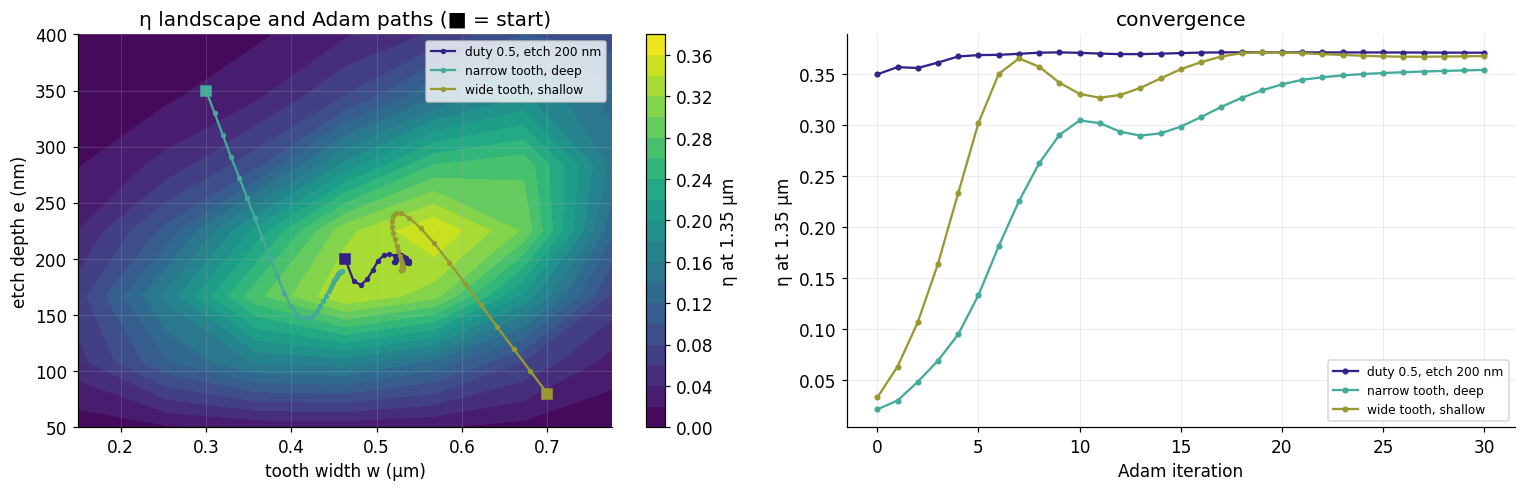

 duty 0.5, etch 200 nm: eta 0.3712 at iteration 18, tooth 0.5298 um, etch 202.8 nm
    narrow tooth, deep: eta 0.3540 at iteration 30, tooth 0.4592 um, etch 189.0 nm
   wide tooth, shallow: eta 0.3712 at iteration 19, tooth 0.5269 um, etch 202.6 nm
best conventional design: duty 0.5, etch 200 nm; landscape maximum 0.3601


In [4]:
# Trajectories on the landscape, and eta vs iteration.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
cs = axes[0].contourf(W_GRID, E_GRID * 1e3, LAND, levels=20, cmap=style.CMAP_DENSITY)
fig.colorbar(cs, ax=axes[0], label="η at 1.35 µm")
for (name, r), c in zip(runs.items(), style.COLOR_CYCLE[::2]):
    th = np.array([h["theta"] for h in r["history"]])
    axes[0].plot(th[:, 0], th[:, 2] * 1e3, "o-", ms=2.5, color=c, label=name)
    axes[0].plot(*[th[0, 0], th[0, 2] * 1e3], "s", color=c, ms=7)
    axes[1].plot([h["eta_best_x0"] for h in r["history"]], "o-", ms=3, color=c, label=name)
axes[0].set(xlabel="tooth width w (µm)", ylabel="etch depth e (nm)", title="η landscape and Adam paths (■ = start)")
axes[1].set(xlabel="Adam iteration", ylabel="η at 1.35 µm", title="convergence")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

BEST_NAME = max(runs, key=lambda k: runs[k]["best"]["eta_best_x0"])
BEST = runs[BEST_NAME]["best"]
for name, r in runs.items():
    b = r["best"]
    print(f"{name:>22}: eta {b['eta_best_x0']:.4f} at iteration {b['iter']}, tooth {b['theta'][0]:.4f} um, "
          f"etch {b['theta'][2] * 1e3:.1f} nm")
print(f"best conventional design: {BEST_NAME}; landscape maximum {LAND.max():.4f}")

## 3. The optimized conventional grating, re-evaluated at res 160

The best design is re-run at res 160 with the `MaterialGrid` representation (the
reference for every final number in this study) and, as an independent cross-check,
with Meep `Block`s. The fiber position is re-optimized at 1.35 µm and then held fixed
for the spectrum. The power budget splits the input into the four places it can go:
up (toward the fiber), down (into the substrate), reflected and transmitted.

 grid, res 160: eta 0.3853 (-4.14 dB), 1-dB band 36 nm; up 0.596, down 0.223, R 0.001, T 0.135; directionality 0.73, mode match 0.65
block, res 160: eta 0.3933 (-4.05 dB), 1-dB band 36 nm; up 0.602, down 0.221, R 0.001, T 0.131; directionality 0.73, mode match 0.65


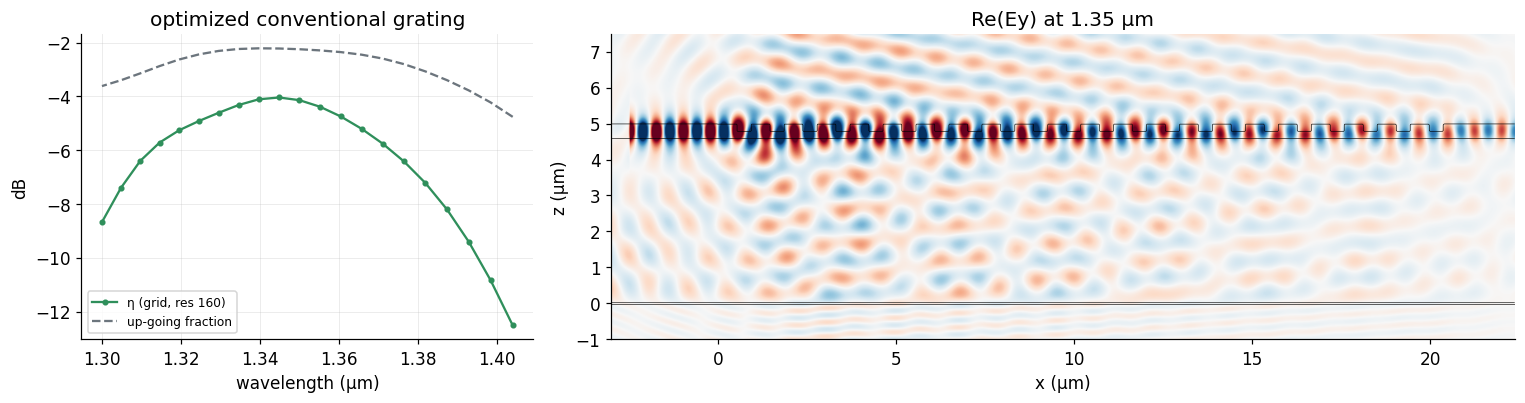

saved meta/data/step2/summary.json


In [5]:
TH = BEST["theta"]
best_design = design(float(TH[0]), float(TH[2]))
final = {kind: sg.cached(CACHE / f"final_{kind}_res160.pkl",
                         lambda: sg.run_forward({**best_design, "resolution": 160}, kind, field_map=(kind == "grid")))
         for kind in ("grid", "block")}


def report(r):
    # eta at 1.35 um (best fiber position), spectrum, 1-dB band, and the power budget.
    i0 = int(np.argmin(np.abs(r["wl"] - 1.35)))
    x0, eta = sg.best_x0(r)
    spec = sg.eta_spectrum(r, x0)
    band = r["wl"][spec >= spec.max() * 10 ** -0.1]
    return {"eta": eta, "eta_db": 10 * np.log10(eta), "x0": x0, "spec": spec, "band_1db_nm": 1e3 * (band.max() - band.min()),
            "up": r["up"][i0], "down": r["down"][i0], "R": r["R"][i0], "T": r["T"][i0],
            "directionality": r["up"][i0] / (r["up"][i0] + r["down"][i0]), "mode_match": eta / r["up"][i0]}


rep = {k: report(v) for k, v in final.items()}
for k, m in rep.items():
    print(f"{k:>5}, res 160: eta {m['eta']:.4f} ({m['eta_db']:.2f} dB), 1-dB band {m['band_1db_nm']:.0f} nm; "
          f"up {m['up']:.3f}, down {m['down']:.3f}, R {m['R']:.3f}, T {m['T']:.3f}; "
          f"directionality {m['directionality']:.2f}, mode match {m['mode_match']:.2f}")
assert rep["grid"]["eta"] <= rep["grid"]["up"] + 1e-6

r = final["grid"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].plot(r["wl"], 10 * np.log10(rep["grid"]["spec"]), "o-", ms=3, color=style.COLOR_SEAGREEN, label="η (grid, res 160)")
axes[0].plot(r["wl"], 10 * np.log10(r["up"]), "--", color=style.COLOR_REFERENCE, label="up-going fraction")
axes[0].set(xlabel="wavelength (µm)", ylabel="dB", title="optimized conventional grating")
axes[0].legend(fontsize=8)
d = r["dom"]
ext = [d["x_left"], d["x_right"], d["z_sub0"], d["z_top"]]
f = np.real(r["field_map"]).T
v = np.abs(f).max() * 0.5
axes[1].imshow(f, origin="lower", cmap=style.CMAP_FIELD, vmin=-v, vmax=v, extent=ext, aspect="auto")
axes[1].contour(np.linspace(ext[0], ext[1], r["eps_map"].shape[0]), np.linspace(ext[2], ext[3], r["eps_map"].shape[1]),
                r["eps_map"].T, levels=[3.0, 8.0], colors="k", linewidths=0.4)
axes[1].set(xlabel="x (µm)", ylabel="z (µm)", title="Re(Ey) at 1.35 µm")
axes[1].grid(False)
fig.tight_layout()
plt.show()

summary = {"res_opt": RES, "period_um": P, "box_um": BOX, "best_seed": BEST_NAME,
           "theta": [float(x) for x in TH], "tooth_um": float(TH[0]), "groove_um": float(P - TH[0]), "etch_um": float(TH[2]),
           "eta_at_res_opt": BEST["eta_best_x0"], "landscape_max": float(LAND.max()),
           "res160": {k: {kk: (vv.tolist() if isinstance(vv, np.ndarray) else float(vv)) for kk, vv in m.items()}
                      for k, m in rep.items()}}
(CACHE / "summary.json").write_text(json.dumps(summary, indent=1))
print("saved meta/data/step2/summary.json")

> **STOP -- this is the conventional baseline that Step 3 has to beat.** Check that Adam
> reached the landscape maximum from every start, and that the res-160 grid and block
> numbers agree within the scatter Step 1 measured for the block representation.